# Indic Climate Stance Detection — XLM-R Class Imbalance
Train and compare:
1. XLM-R with ordinary Cross-Entropy
2. XLM-R with class-weighted Cross-Entropy

Choose Hindi or Bengali and run all cells in order. Labels: `0=Against`, `1=Favour`, `2=None`.

Protocol: calculate weights from training labels only. Never resample validation/test. This notebook does not manually correct translations.

## 1. Install dependencies

In [16]:
!pip -q install -U transformers accelerate scikit-learn pandas matplotlib seaborn

## 2. Imports, seed, and GPU

In [17]:
import os, json, random, zipfile, copy, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

SEED=42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type=="cuda": print(torch.cuda.get_device_name(0))
else: print("Enable GPU: Runtime > Change runtime type > T4 GPU")

Device: cuda
Tesla T4


## 3. Upload and extract Stage 1 cleaned ZIP

In [18]:
from google.colab import files
uploaded=files.upload()  # Upload indic_climate_stage1_cleaned.zip
zips=[n for n in uploaded if n.lower().endswith(".zip")]
if not zips: raise FileNotFoundError("Upload the Stage 1 cleaned ZIP.")
DATA_DIR=Path("/content/indic_climate_stage1_cleaned")
DATA_DIR.mkdir(exist_ok=True, parents=True)
with zipfile.ZipFile(zips[0]) as zf: zf.extractall(DATA_DIR)
print(sorted(p.name for p in DATA_DIR.glob("*.csv")))

Saving indic_climate_stage1_cleaned.zip to indic_climate_stage1_cleaned (1).zip
['bengali_test.csv', 'bengali_train.csv', 'bengali_val.csv', 'cross_language_integrity_check.csv', 'hindi_test.csv', 'hindi_train.csv', 'hindi_val.csv', 'label_distribution.csv', 'stage1_file_audit.csv']


## 4. Choose language and load data

In [19]:
LANGUAGE="bengali"  # Change to "bengali" for Bengali experiment
assert LANGUAGE in ("hindi","bengali")
def load_split(split):
    p=DATA_DIR/f"{LANGUAGE}_{split}.csv"
    if not p.exists(): raise FileNotFoundError(p)
    d=pd.read_csv(p)
    required={"example_id","split","language","original_text","text","label"}
    if not required.issubset(d.columns): raise ValueError(f"Missing columns: {required-set(d.columns)}")
    d=d.dropna(subset=["text","label"]).copy()
    d["text"]=d["text"].astype(str).str.strip()
    d["label"]=d["label"].astype(int)
    d=d[d.text.ne("")].reset_index(drop=True)
    if not set(d.label.unique()).issubset({0,1,2}): raise ValueError("Labels must be 0,1,2")
    return d
train_df=load_split("train"); val_df=load_split("val"); test_df=load_split("test")
print(LANGUAGE, train_df.shape, val_df.shape, test_df.shape)
display(train_df.head())

bengali (2871, 6) (354, 6) (355, 6)


,example_id,split,language,original_text,text,label
0,train_00000,train,bengali,Agriculture needs changes to help save climate...,জলবায়ু ও কৃষকদের বাঁচাতে কৃষিতে পরিবর্তন প্রয...,1
1,train_00001,train,bengali,#Cop21Napoli: happening now side event on #cli...,#Cop21Napoli: ভূমধ্যসাগরে জলবায়ু অ্যাকশনঃ পরি...,1
2,train_00002,train,bengali,RT paulnewnham: #FFXAbuDhabi has started! Chef...,আরটি পলনিউনহামঃ #FFXAbuDhabi শুরু হয়ে গেছে! জ...,1
3,train_00003,train,bengali,@fitzhunter We need a national plan for combat...,জলবায়ু পরিবর্তনের বিরুদ্ধে লড়াই করার জন্য আম...,1
4,train_00004,train,bengali,"In the speech, delivered by Gov. Gen. Julie Pa...",সিনেটে গভর্নর জেনারেল জুলি পায়েটের দেওয়া ভাষ...,1


## 5. Inspect class distributions

TRAIN


,label,class,count,percentage
0,0,Against,308,10.73
1,1,Favour,2294,79.90
2,2,None,269,9.37


VALIDATION


,label,class,count,percentage
0,0,Against,44,12.43
1,1,Favour,284,80.23
2,2,None,26,7.34


TEST


,label,class,count,percentage
0,0,Against,35,9.86
1,1,Favour,285,80.28
2,2,None,35,9.86


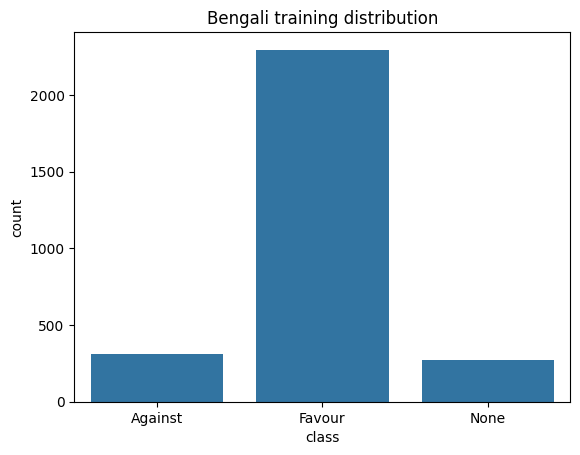

In [20]:
LABEL_NAMES=["Against","Favour","None"]
def distribution(d,name):
    c=d.label.value_counts().reindex([0,1,2],fill_value=0)
    out=pd.DataFrame({"label":[0,1,2],"class":LABEL_NAMES,"count":c.values,
                      "percentage":(c.values/len(d)*100).round(2)})
    print(name); display(out); return out
train_dist=distribution(train_df,"TRAIN")
val_dist=distribution(val_df,"VALIDATION")
test_dist=distribution(test_df,"TEST")
sns.barplot(data=train_dist,x="class",y="count")
plt.title(f"{LANGUAGE.title()} training distribution"); plt.show()

## 6. Calculate class weights from TRAINING labels only

In [21]:
classes=np.array([0,1,2])
y_train=train_df.label.to_numpy()
weights_np=compute_class_weight(class_weight="balanced",classes=classes,y=y_train)
class_weights=torch.tensor(weights_np,dtype=torch.float32,device=device)
display(pd.DataFrame({"label":classes,"class":LABEL_NAMES,
 "train_count":[int((y_train==c).sum()) for c in classes],"weight":weights_np}))
print("Weights:",weights_np)

,label,class,train_count,weight
0,0,Against,308,3.107143
1,1,Favour,2294,0.417175
2,2,None,269,3.557621


Weights: [3.10714286 0.41717524 3.55762082]


## 7. Tokenizer and datasets

In [22]:
MODEL_NAME="FacebookAI/xlm-roberta-base"
MAX_LENGTH=160
BATCH_SIZE=8  # Try 16 only if GPU memory allows
tokenizer=AutoTokenizer.from_pretrained(MODEL_NAME)
class StanceDataset(Dataset):
    def __init__(self,df):
        self.texts=df.text.astype(str).tolist()
        self.labels=df.label.astype(int).tolist()
    def __len__(self): return len(self.labels)
    def __getitem__(self,i):
        x=tokenizer(self.texts[i],truncation=True,max_length=MAX_LENGTH,
                    padding="max_length",return_tensors="pt")
        item={k:v.squeeze(0) for k,v in x.items()}
        item["labels"]=torch.tensor(self.labels[i],dtype=torch.long)
        return item
train_loader=DataLoader(StanceDataset(train_df),batch_size=BATCH_SIZE,shuffle=True)
val_loader=DataLoader(StanceDataset(val_df),batch_size=BATCH_SIZE,shuffle=False)
test_loader=DataLoader(StanceDataset(test_df),batch_size=BATCH_SIZE,shuffle=False)
print(len(train_loader),len(val_loader),len(test_loader))

359 45 45


## 8. Evaluation and training functions

In [23]:
def evaluate(model,loader):
    model.eval(); ys=[]; ps=[]; total=0
    eval_loss=nn.CrossEntropyLoss()
    with torch.no_grad():
        for batch in loader:
            batch={k:v.to(device) for k,v in batch.items()}
            labels=batch.pop("labels")
            out=model(**batch)
            total+=eval_loss(out.logits,labels).item()
            ys.extend(labels.cpu().numpy()); ps.extend(out.logits.argmax(1).cpu().numpy())
    return {"loss":total/max(len(loader),1),"accuracy":accuracy_score(ys,ps),
            "macro_f1":f1_score(ys,ps,labels=[0,1,2],average="macro",zero_division=0),
            "labels":np.array(ys),"predictions":np.array(ps)}

def train_experiment(name,weighted,epochs=3,lr=2e-5):
    print(f"Training {name}; weighted={weighted}")
    model=AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,num_labels=3,
        id2label={0:"Against",1:"Favour",2:"None"},
        label2id={"Against":0,"Favour":1,"None":2}).to(device)
    loss_fn=nn.CrossEntropyLoss(weight=class_weights) if weighted else nn.CrossEntropyLoss()
    optimizer=torch.optim.AdamW(model.parameters(),lr=lr,weight_decay=0.01)
    steps=len(train_loader)*epochs
    scheduler=get_linear_schedule_with_warmup(optimizer,int(.1*steps),steps)
    best=-1; best_state=None; history=[]
    for epoch in range(epochs):
        model.train(); total=0
        for batch in train_loader:
            batch={k:v.to(device) for k,v in batch.items()}
            labels=batch.pop("labels")
            optimizer.zero_grad(set_to_none=True)
            logits=model(**batch).logits
            loss=loss_fn(logits,labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
            optimizer.step(); scheduler.step()
            total+=loss.item()
        vm=evaluate(model,val_loader)
        row={"epoch":epoch+1,"train_loss":total/max(len(train_loader),1),
             "val_loss":vm["loss"],"val_accuracy":vm["accuracy"],"val_macro_f1":vm["macro_f1"]}
        history.append(row); print(row)
        if vm["macro_f1"]>best:
            best=vm["macro_f1"]; best_state=copy.deepcopy(model.state_dict())
    if best_state is not None: model.load_state_dict(best_state)
    return model,pd.DataFrame(history)

## 9. Experiment 1 — standard Cross-Entropy

In [24]:
EPOCHS=3
LEARNING_RATE=2e-5
baseline_model,baseline_history=train_experiment("XLM-R standard CE",False,EPOCHS,LEARNING_RATE)
display(baseline_history)

Training XLM-R standard CE; weighted=False


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'epoch': 1, 'train_loss': 0.7560363354000541, 'val_loss': 0.6654739770624373, 'val_accuracy': 0.8022598870056498, 'val_macro_f1': 0.296760710553814}
{'epoch': 2, 'train_loss': 0.653138225913712, 'val_loss': 0.6284481268790033, 'val_accuracy': 0.8022598870056498, 'val_macro_f1': 0.296760710553814}
{'epoch': 3, 'train_loss': 0.6242018542291394, 'val_loss': 0.598039945297771, 'val_accuracy': 0.8022598870056498, 'val_macro_f1': 0.296760710553814}


,epoch,train_loss,val_loss,val_accuracy,val_macro_f1
0,1,0.756036,0.665474,0.80226,0.296761
1,2,0.653138,0.628448,0.80226,0.296761
2,3,0.624202,0.598040,0.80226,0.296761


## 10. Experiment 2 — weighted Cross-Entropy

In [25]:
weighted_model,weighted_history=train_experiment("XLM-R weighted CE",True,EPOCHS,LEARNING_RATE)
display(weighted_history)

Training XLM-R weighted CE; weighted=True


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'epoch': 1, 'train_loss': 1.0922982013657232, 'val_loss': 0.9905186931292216, 'val_accuracy': 0.8022598870056498, 'val_macro_f1': 0.296760710553814}
{'epoch': 2, 'train_loss': 1.089395717325981, 'val_loss': 1.0304175006018745, 'val_accuracy': 0.8022598870056498, 'val_macro_f1': 0.296760710553814}
{'epoch': 3, 'train_loss': 1.0891549205381559, 'val_loss': 1.0097525305218167, 'val_accuracy': 0.8022598870056498, 'val_macro_f1': 0.296760710553814}


,epoch,train_loss,val_loss,val_accuracy,val_macro_f1
0,1,1.092298,0.990519,0.80226,0.296761
1,2,1.089396,1.030418,0.80226,0.296761
2,3,1.089155,1.009753,0.80226,0.296761


## 11. Test comparison

In [26]:
baseline_test=evaluate(baseline_model,test_loader)
weighted_test=evaluate(weighted_model,test_loader)
comparison=pd.DataFrame([
 {"experiment":"Standard Cross-Entropy","accuracy":baseline_test["accuracy"],"macro_f1":baseline_test["macro_f1"]},
 {"experiment":"Class-Weighted Cross-Entropy","accuracy":weighted_test["accuracy"],"macro_f1":weighted_test["macro_f1"]}
])
display(comparison)

,experiment,accuracy,macro_f1
0,Standard Cross-Entropy,0.802817,0.296875
1,Class-Weighted Cross-Entropy,0.802817,0.296875


## 12. Per-class report and confusion matrices

Standard CE
              precision    recall  f1-score   support

     Against     0.0000    0.0000    0.0000        35
      Favour     0.8028    1.0000    0.8906       285
        None     0.0000    0.0000    0.0000        35

    accuracy                         0.8028       355
   macro avg     0.2676    0.3333    0.2969       355
weighted avg     0.6445    0.8028    0.7150       355



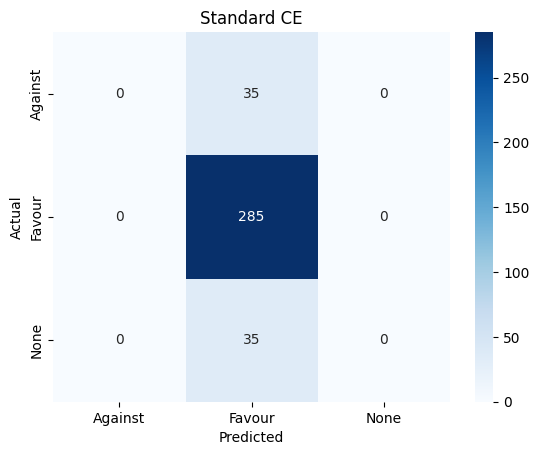

Weighted CE
              precision    recall  f1-score   support

     Against     0.0000    0.0000    0.0000        35
      Favour     0.8028    1.0000    0.8906       285
        None     0.0000    0.0000    0.0000        35

    accuracy                         0.8028       355
   macro avg     0.2676    0.3333    0.2969       355
weighted avg     0.6445    0.8028    0.7150       355



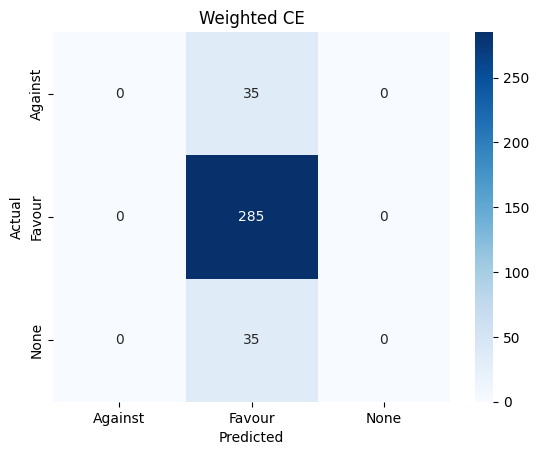

In [27]:
def detailed_report(name,m):
    print(name)
    print(classification_report(m["labels"],m["predictions"],labels=[0,1,2],
       target_names=LABEL_NAMES,digits=4,zero_division=0))
    cm=confusion_matrix(m["labels"],m["predictions"],labels=[0,1,2])
    sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",xticklabels=LABEL_NAMES,yticklabels=LABEL_NAMES)
    plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title(name); plt.show()
detailed_report("Standard CE",baseline_test)
detailed_report("Weighted CE",weighted_test)

## 13. Save models and experiment results

In [28]:
OUT=Path(f"/content/xlmr_{LANGUAGE}_imbalance_results")
OUT.mkdir(exist_ok=True,parents=True)
baseline_model.save_pretrained(OUT/"baseline_standard_ce")
tokenizer.save_pretrained(OUT/"baseline_standard_ce")
weighted_model.save_pretrained(OUT/"weighted_cross_entropy")
tokenizer.save_pretrained(OUT/"weighted_cross_entropy")
baseline_history.to_csv(OUT/"baseline_history.csv",index=False)
weighted_history.to_csv(OUT/"weighted_history.csv",index=False)
comparison.to_csv(OUT/"test_comparison.csv",index=False)
config={"language":LANGUAGE,"model":MODEL_NAME,"max_length":MAX_LENGTH,
 "batch_size":BATCH_SIZE,"epochs":EPOCHS,"learning_rate":LEARNING_RATE,
 "labels":{"0":"Against","1":"Favour","2":"None"},
 "training_class_weights":{str(int(c)):float(w) for c,w in zip(classes,weights_np)},
 "weights_calculated_from":"training split only","validation_test_resampling":False,"seed":SEED}
(OUT/"config.json").write_text(json.dumps(config,indent=2))
print("Saved:",OUT)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved: /content/xlmr_bengali_imbalance_results


## 14. Download results

In [29]:
# ==========================================
# EXPORT ONLY ESSENTIAL RESULTS FOR ANALYSIS
# No model weights or checkpoint files
# ==========================================

import json
import zipfile
from pathlib import Path
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)

ANALYSIS_DIR = Path(f"/content/{LANGUAGE}_analysis_results")
ANALYSIS_DIR.mkdir(exist_ok=True, parents=True)

# 1. Collect predictions and probabilities
def export_predictions(model, loader, dataframe, experiment, split):

    model.eval()
    actual, predicted, probabilities = [], [], []

    with torch.no_grad():
        for batch in loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            labels = batch.pop("labels")

            logits = model(**batch).logits
            probs = torch.softmax(logits, dim=1)

            actual.extend(labels.cpu().numpy())
            predicted.extend(logits.argmax(dim=1).cpu().numpy())
            probabilities.extend(probs.cpu().numpy())

    if len(dataframe) != len(actual):
        raise ValueError(
            f"Prediction count mismatch for {experiment}, {split}"
        )

    result = dataframe[
        ["example_id", "original_text", "text", "label"]
    ].copy().reset_index(drop=True)

    result.rename(columns={"label": "actual_label"}, inplace=True)

    result["predicted_label"] = predicted
    result["correct"] = (
        result["actual_label"] == result["predicted_label"]
    )

    probs = np.asarray(probabilities)

    result["prob_against"] = probs[:, 0]
    result["prob_favour"] = probs[:, 1]
    result["prob_none"] = probs[:, 2]

    result.insert(0, "experiment", experiment)
    result.insert(1, "split", split)

    return result


# 2. Generate predictions for both models
all_predictions = []
all_metrics = []

experiments = [
    ("Standard_CE", baseline_model),
    ("Weighted_CE", weighted_model)
]

splits = [
    ("Validation", val_loader, val_df),
    ("Test", test_loader, test_df)
]

for exp_name, model in experiments:

    for split_name, loader, dataframe in splits:

        predictions = export_predictions(
            model, loader, dataframe, exp_name, split_name
        )

        all_predictions.append(predictions)

        y_true = predictions["actual_label"]
        y_pred = predictions["predicted_label"]

        metrics = {
            "experiment": exp_name,
            "split": split_name,
            "accuracy": float(accuracy_score(y_true, y_pred)),
            "macro_f1": float(f1_score(
                y_true, y_pred,
                labels=[0, 1, 2],
                average="macro",
                zero_division=0
            )),
            "classification_report": classification_report(
                y_true, y_pred,
                labels=[0, 1, 2],
                target_names=LABEL_NAMES,
                output_dict=True,
                zero_division=0
            ),
            "confusion_matrix": confusion_matrix(
                y_true, y_pred, labels=[0, 1, 2]
            ).tolist()
        }

        all_metrics.append(metrics)


# 3. Save combined prediction file
pd.concat(
    all_predictions,
    ignore_index=True
).to_csv(
    ANALYSIS_DIR / "predictions.csv",
    index=False
)


# 4. Save detailed metrics and confusion matrices
with open(
    ANALYSIS_DIR / "metrics.json", "w", encoding="utf-8"
) as f:
    json.dump(all_metrics, f, indent=2, ensure_ascii=False)


# 5. Save training histories
baseline_history.to_csv(
    ANALYSIS_DIR / "baseline_history.csv", index=False
)

weighted_history.to_csv(
    ANALYSIS_DIR / "weighted_history.csv", index=False
)


# 6. Save dataset distributions
distribution_rows = []

for split_name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    counts = df["label"].value_counts().reindex(
        [0, 1, 2], fill_value=0
    )

    for label, count in counts.items():
        distribution_rows.append({
            "split": split_name,
            "label_id": int(label),
            "class": LABEL_NAMES[int(label)],
            "count": int(count)
        })

pd.DataFrame(distribution_rows).to_csv(
    ANALYSIS_DIR / "class_distribution.csv",
    index=False
)


# 7. Save experiment configuration
config = {
    "language": LANGUAGE,
    "model": MODEL_NAME,
    "epochs": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "max_length": MAX_LENGTH,
    "seed": SEED,
    "class_weights": {
        str(int(c)): float(w)
        for c, w in zip(classes, weights_np)
    }
}

with open(
    ANALYSIS_DIR / "config.json", "w", encoding="utf-8"
) as f:
    json.dump(config, f, indent=2)


# 8. Create SMALL ZIP — excludes model checkpoints
ZIP_PATH = Path(f"{LANGUAGE}_analysis_only.zip")

with zipfile.ZipFile(
    ZIP_PATH, "w", zipfile.ZIP_DEFLATED
) as zip_file:

    for file in ANALYSIS_DIR.iterdir():
        if file.is_file():
            zip_file.write(file, arcname=file.name)


print("Analysis package created:", ZIP_PATH)
print("Size (MB):", round(ZIP_PATH.stat().st_size / (1024**2), 2))

# 9. Download only this compact package
from google.colab import files
files.download(str(ZIP_PATH))

/tmp/ipykernel_493/3729609410.py:46: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  result.rename(columns={"label": "actual_label"}, inplace=True)
/tmp/ipykernel_493/3729609410.py:46: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  result.rename(columns={"label": "actual_label"}, inplace=True)
/tmp/ipykernel_493/3729609410.py:46: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  result.rename(columns={"label": "actual_label"}, inplace=True)


Analysis package created: bengali_analysis_only.zip
Size (MB): 0.32


/tmp/ipykernel_493/3729609410.py:46: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  result.rename(columns={"label": "actual_label"}, inplace=True)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 15. How to report results
- Report both experiments, not only the better one.
- Macro-F1 is the primary metric because classes are imbalanced.
- Compare per-class precision, recall and F1, especially Against and None.
- Weighted loss may improve minority recall but can reduce majority-class performance; report the measured outcome.
- Run the notebook again with `LANGUAGE="bengali"` for the Bengali experiment.
- This notebook has not been executed on your Colab runtime. Run cells in order and retain the output logs for your report.